<a href="https://colab.research.google.com/github/bek180/computer-vision-projects/blob/main/%D0%BF%D0%B5%D1%80%D0%B2%D1%8B%D0%B9%20%D0%BF%D1%80%D0%BE%D0%B1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

проб

In [ ]:
import numpy as np

In [ ]:
#a1 числа 0–19 и только чётные
a = np.arange(20)

print("All numbers:", a)
print("Even numbers:", a[a % 2 == 0])

All numbers: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19]
Even numbers: [ 0  2  4  6  8 10 12 14 16 18]


In [ ]:
#a2 случайная матрица5×5


a = np.random.randint(0, 101, size=(5, 5))

print(a)

print("Mean:", np.mean(a))
print("Max:", np.max(a))
print("Min:", np.min(a))
print("Standard deviation:", np.std(a))

[[  6  40  20  56  40]
 [ 21  72  55  44  51]
 [ 29   8  82  78  69]
 [ 62  79  82  91 100]
 [ 72  71  27  37  78]]
Mean: 54.8
Max: 100
Min: 6
Standard deviation: 25.964591273501686


In [ ]:
#a3 возведение элементов в квадрат без цикла
a = np.array([1, 2, 3, 4, 5])

squared = a ** 2

print(squared)

[ 1  4  9 16 25]


In [ ]:
#a4 транспонирование
a = np.arange(12).reshape(3, 4)

print("Original:")
print(a)
print("Shape before:", a.shape)

transposed = a.T

print("Transposed:")
print(transposed)
print("Shape after:", transposed.shape)

Original:
[[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]
Shape before: (3, 4)
Transposed:
[[ 0  4  8]
 [ 1  5  9]
 [ 2  6 10]
 [ 3  7 11]]
Shape after: (4, 3)


In [ ]:
#a5
a = np.array([
    [1, 2, 3],
    [4, 5, 6],
    [7, 8, 9]
])

b = np.array([
    [9, 8, 7],
    [6, 5, 4],
    [3, 2, 1]
])

result = (a + b) * 2

print(result)

[[20 20 20]
 [20 20 20]
 [20 20 20]]


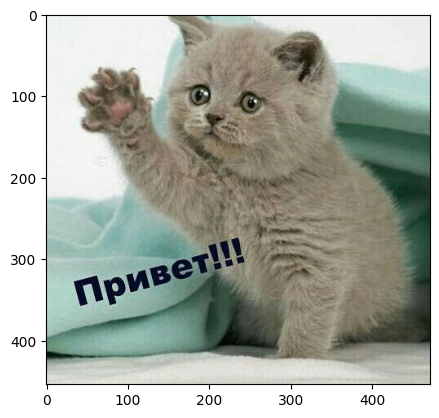

In [ ]:
#b block
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

img = np.array(Image.open("/content/Image.jpg").convert("RGB"))
plt.imshow(img)
plt.show()

Height: 454
Width: 471
Channels: 3


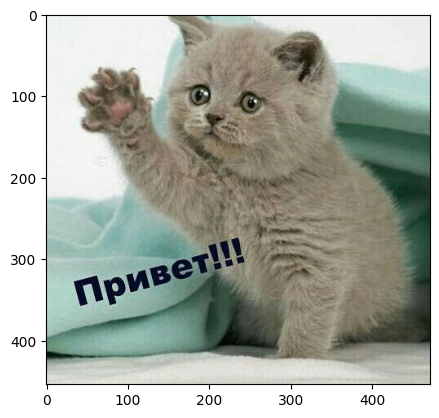

In [ ]:
#b1
height, width, channels = img.shape

print("Height:", height)
print("Width:", width)
print("Channels:", channels)

plt.imshow(img)
plt.show()

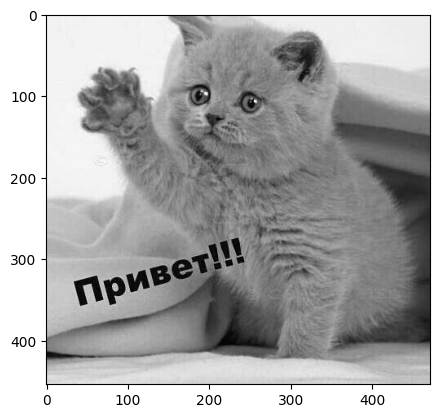

In [ ]:
#b2
def to_grayscale(img):
    R = img[:, :, 0]
    G = img[:, :, 1]
    B = img[:, :, 2]

    gray = 0.299 * R + 0.587 * G + 0.114 * B

    return gray.astype(np.uint8)

gray_img = to_grayscale(img)

Image.fromarray(gray_img).show()
plt.imshow(gray_img, cmap='gray')
plt.show()

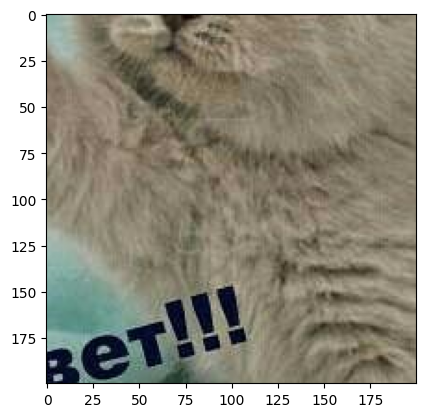

In [ ]:
#b3
def crop_center(img, size):
    h, w = img.shape[:2] #slipping h and w

    start_y = (h - size) // 2
    start_x = (w - size) // 2

    return img[
        start_y:start_y + size,
        start_x:start_x + size
    ]

cropped = crop_center(img, 200)

Image.fromarray(cropped).show()
plt.imshow(cropped)
plt.show()

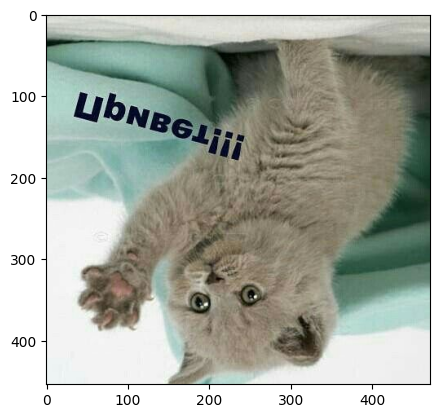

In [ ]:
#b4
flipped = img[::-1, :, :]

Image.fromarray(flipped).show()
plt.imshow(flipped)
plt.show()


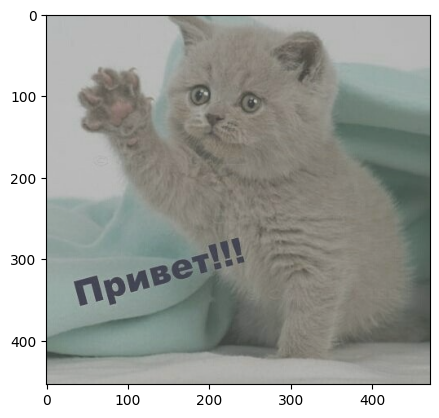

In [ ]:
contrast = 128 + (img.astype(float) - 128) * 0.5

contrast = np.clip(contrast, 0, 255).astype(np.uint8)

Image.fromarray(contrast).show()

plt.imshow(contrast)
plt.show()

In [ ]:
#C
import pandas as pd

data = {
    "filename": [f"img_{i:03d}.jpg" for i in range(1, 13)],
    "label": [
        "cat", "dog", "cat", "bird", "dog", "dog",
        "cat", "bird", "cat", "dog", "bird", "cat"
    ],
    "width": [224, 224, 256, 224, 300, 224, 224, 180, 256, 224, 200, 224],
    "height": [224, 224, 256, 224, 300, 224, 224, 180, 256, 224, 200, 224],
    "brightness": [120, 95, 140, 110, 88, 130, 145, 100, 115, 90, 105, 150],
}

df = pd.DataFrame(data)

print(df)

       filename label  width  height  brightness
0   img_001.jpg   cat    224     224         120
1   img_002.jpg   dog    224     224          95
2   img_003.jpg   cat    256     256         140
3   img_004.jpg  bird    224     224         110
4   img_005.jpg   dog    300     300          88
5   img_006.jpg   dog    224     224         130
6   img_007.jpg   cat    224     224         145
7   img_008.jpg  bird    180     180         100
8   img_009.jpg   cat    256     256         115
9   img_010.jpg   dog    224     224          90
10  img_011.jpg  bird    200     200         105
11  img_012.jpg   cat    224     224         150


In [ ]:
#c1
print(df["label"].value_counts())

label
cat     5
dog     4
bird    3
Name: count, dtype: int64


In [ ]:
#c2
dark_images = df[df["brightness"] < 100]

print(dark_images)

      filename label  width  height  brightness
1  img_002.jpg   dog    224     224          95
4  img_005.jpg   dog    300     300          88
9  img_010.jpg   dog    224     224          90


In [ ]:
#c3 среднняя яркость
average_brightness = df.groupby("label")["brightness"].mean()

print(average_brightness)

label
bird    105.00
cat     134.00
dog     100.75
Name: brightness, dtype: float64


In [ ]:
#c4 area
df["area"] = df["width"] * df["height"]

print(df)

       filename label  width  height  brightness   area
0   img_001.jpg   cat    224     224         120  50176
1   img_002.jpg   dog    224     224          95  50176
2   img_003.jpg   cat    256     256         140  65536
3   img_004.jpg  bird    224     224         110  50176
4   img_005.jpg   dog    300     300          88  90000
5   img_006.jpg   dog    224     224         130  50176
6   img_007.jpg   cat    224     224         145  50176
7   img_008.jpg  bird    180     180         100  32400
8   img_009.jpg   cat    256     256         115  65536
9   img_010.jpg   dog    224     224          90  50176
10  img_011.jpg  bird    200     200         105  40000
11  img_012.jpg   cat    224     224         150  50176


In [ ]:
#c5 top-3самых ярких
top3 = df.sort_values(
    by="brightness",
    ascending=False
).head(3)

print(top3)

       filename label  width  height  brightness   area
11  img_012.jpg   cat    224     224         150  50176
6   img_007.jpg   cat    224     224         145  50176
2   img_003.jpg   cat    256     256         140  65536
